# 04 · Métricas y visualización de datos con Streamlit (EA4)

**Proyecto:** Análisis Descriptivo de la Estancia Hospitalaria y Factores Operativos en Admisiones Médicas.

## 1. Introducción y contexto

**Necesidad analítica (escenario hipotético).** La Dirección de Gestión Operativa y Control de Camas de un centro hospitalario necesitaría caracterizar la duración de la estancia y el depósito de admisión según factores clínicos y operativos. El análisis es **descriptivo**: no establece causalidad, eficiencia clínica ni efectos operativos.

**Pregunta principal.** ¿Cómo varían la duración de la estancia hospitalaria y el valor del depósito de admisión según el departamento médico, el nivel de severidad de la enfermedad y los recursos de personal disponibles en los registros del dataset seleccionado?

| ID | Pregunta | Métrica | Variables | Tabla fuente (`EA4/results/tables/`) | Gráfico en la app |
|---|---|---|---|---|---|
| P1 | ¿Cómo varían la estancia y el depósito entre departamentos? | Media y mediana de estancia y depósito; días-paciente y su participación | `department`, `stay_in_days`, `admission_deposit` | `results_by_department.csv`, `results_patient_days_by_department.csv` | Barras horizontales, barras agrupadas (% admisiones vs. % días-paciente), cajas |
| P2 | ¿Qué diferencias se observan según la severidad? | Media/mediana por severidad; estancia esperada por composición | `severity_of_illness`, `department`, estancia, depósito | `results_by_severity.csv`, `results_severity_expected_stay.csv` | Barras observada vs. esperada, puntos, cajas |
| P3 | ¿Cómo se distribuyen según la disponibilidad de personal? | Media/mediana por grupo; ρ de Spearman | `staff_available`, `staff_availability_group` | `results_by_staff_availability.csv`, `results_by_staff_level.csv`, `results_spearman_correlations.csv` | Puntos, barras por nivel, tarjetas KPI de ρ |
| P4 | ¿Qué patrones aparecen al cruzar departamento y severidad? | Métricas por combinación | `department`, `severity_of_illness` | `results_by_department_severity.csv`, cubo de filtros | Mapa de calor |
| P5 | ¿Qué utilidad aportan los indicadores derivados? | Rango de estancia, puntaje exploratorio, depósito y visitas por día, desviación frente al departamento | variables derivadas de EA3 | `results_by_stay_range.csv`, `results_by_complexity_score.csv`, `results_by_department_indicators.csv`, `results_histograms.csv` | Barras, histogramas, caja con la muestra (rotulada) |
| PC1 | ¿Cómo se distribuyen la estancia y el depósito? | Media, mediana, desviación, cuartiles, atípicos (Tukey) | `stay_in_days`, `admission_deposit` | `results_distribution_summary.csv`, `results_histograms.csv` | Histogramas con todos los registros |
| PC2 | ¿Qué otras variables se relacionan con la estancia y el depósito? | Métricas por grupo, η², ρ de Spearman | sala, edad, género, admisión, seguro, condición, habitaciones extra, visitantes, personal | `results_pc2_group_metrics.csv`, `results_eta_squared.csv`, `results_spearman_correlations.csv` | Barras de η², barras de ρ, barras por categoría |
| PC3 | ¿Qué limitaciones de calidad condicionan la interpretación? | Nulos, conversiones, indicadores no calculables | todas | `results_data_quality.csv`, metadatos | Barras de % de nulos, tabla de advertencias |

**Relación entre AE3, este notebook y la app.** El notebook reutiliza `HFDatasetLoader`, `transformations.apply_all` y `enrichment.apply_enrichment` (EA1-EA3) sobre el dataset completo, recalcula las tablas de EA3 con el mismo código, añade las métricas de EA4 y exporta todo a `EA4/`. La app (`EA4/app.py`) solo lee esos archivos: no descarga Hugging Face.

**Resultados que se generan:** tablas agregadas (`EA4/results/tables/`), un cubo agregado para los filtros, una muestra sistemática de ≤ 100.000 registros (`EA4/data/processed/`), los metadatos de la ejecución y el reporte `EA4/reports/ea4-summary.txt`.

## 2. Preparación e importaciones

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
# Se busca un archivo que solo existe en el src de la raíz (EA4 también tiene su propio src/config.py).
while ROOT != ROOT.parent and not (ROOT / "src" / "data" / "huggingface_loader.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # «src» = paquete de EA1-EA3 y «EA4.src» = paquete de EA4

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# EA1-EA3 (se reutilizan, no se reimplementan)
from src.data.dataset_io import make_loader
from src.data import transformations as tr
from src.data import enrichment as en
from src.analysis.quality import compare_dataframes
from src.utils.reporter import DatasetSummarizer
# EA4
from EA4.src import config as ea4
from EA4.src.metrics import business_metrics as bm, insights as ins, table_builder as tb
from EA4.src.data import data_loader as dl
from EA4.src.visualization import charts as ch
from EA4.src.visualization.dashboard_streamlit import Filters, HospitalDashboard

def mostrar(fig):
    """Imagen estática (visible en GitHub) si kaleido está disponible; si no, figura interactiva."""
    try:
        display(Image(fig.to_image(format="png", width=1000, scale=1)))
    except Exception:
        fig.show()

print("Raíz del proyecto:", ROOT.name, "| carpeta EA4:", ea4.EA4_DIR.relative_to(ROOT))

D:\Documents\Study\IUDigital\proyecto_integrado_3\healthcare-hospital-stay-analytics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raíz del proyecto: healthcare-hospital-stay-analytics | carpeta EA4: EA4


## 3. Carga del dataset completo (reutiliza EA1)

`make_loader()` crea el `HFDatasetLoader` de EA1 con el identificador, la configuración y el split verificados. Se guarda una copia profunda del original (`raw_original`) para las comparaciones de calidad (PC3).

In [2]:
loader = make_loader()
print("Configuraciones y splits disponibles:", loader.available_splits())
raw = loader.load()
info = loader.info()
raw_original = raw.copy(deep=True)
print(f"Dataset: {info['dataset_id']} | configuración: {info['config']} | split: {info['split']} | {info['muestreo']}")
print(f"Dimensiones originales: {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
raw.head()

Configuraciones y splits disponibles: {'default': ['train']}


Dataset: Nicolybgs/healthcare_data | configuración: default | split: train | dataset completo (sin muestreo)
Dimensiones originales: 500,000 filas x 15 columnas


,Available Extra Rooms in Hospital,Department,Ward_Facility_Code,doctor_name,staff_available,patientid,Age,gender,Type of Admission,Severity of Illness,health_conditions,Visitors with Patient,Insurance,Admission_Deposit,Stay (in days)
0,4,gynecology,D,Dr Sophia,0,33070,41-50,Female,Trauma,Extreme,Diabetes,4,Yes,2966.408696,8
1,4,gynecology,B,Dr Sophia,2,34808,31-40,Female,Trauma,Minor,Heart disease,2,No,3554.835677,9
2,2,gynecology,B,Dr Sophia,8,44577,21-30,Female,Trauma,Extreme,Diabetes,2,Yes,5624.733654,7
3,4,gynecology,D,Dr Olivia,7,3695,31-40,Female,Urgent,Moderate,None,4,No,4814.149231,8
4,2,anesthesia,E,Dr Mark,10,108956,71-80,Male,Trauma,Moderate,Diabetes,2,No,5169.269637,34


## 4. Transformación y enriquecimiento (reutiliza EA3)

Se aplican exactamente las funciones de EA3: las seis transformaciones de `apply_all` y los seis enriquecimientos de `apply_enrichment` (mismas fórmulas y umbrales, incluida la segmentación de personal Bajo 0-3, Medio 4-6, Alto 7+). EA3 no implementó una variable `staff_availability_level`; como nivel se usan los 11 valores originales de `staff_available`.

In [3]:
processed, tlog = tr.apply_all(raw)
df, elog = en.apply_enrichment(processed)
log_tbl = pd.DataFrame([{"paso": r["paso"], "filas_antes": r["filas_antes"], "filas_despues": r["filas_despues"],
                         "columnas_antes": r["columnas_antes"], "columnas_despues": r["columnas_despues"]} for r in tlog + elog])
display(log_tbl)
print(f"Columnas: {raw.shape[1]} originales -> {processed.shape[1]} transformadas -> {df.shape[1]} enriquecidas | filas: {len(raw):,} -> {len(df):,}")

,paso,filas_antes,filas_despues,columnas_antes,columnas_despues
0,strip_text_values,500000,500000,15,15
1,convert_numeric_types,500000,500000,15,15
2,drop_exact_duplicates,500000,500000,15,15
3,normalize_column_names,500000,500000,15,15
4,standardize_categories,500000,500000,15,15
5,add_staff_availability_group,500000,500000,15,16
6,deposit_per_stay_day,500000,500000,16,17
7,visitors_per_day,500000,500000,17,18
8,stay_range,500000,500000,18,19
9,clinical_complexity_score,500000,500000,19,22


Columnas: 15 originales -> 16 transformadas -> 25 enriquecidas | filas: 500,000 -> 500,000


## 5. Verificación del DataFrame enriquecido

In [4]:
faltan = tb.check_required_columns(df)
assert not faltan, f"Faltan columnas requeridas: {faltan}"
print("Todas las variables requeridas existen:", len(tb.REQUIRED_COLUMNS), "columnas verificadas.")
cmp = compare_dataframes(raw_original, df)
display(cmp["dimensiones"])
print("Columnas nuevas:", cmp["columnas_nuevas"])
pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2)})

Todas las variables requeridas existen: 21 columnas verificadas.


,antes,despues
filas,500000,500000
columnas,15,25
duplicados_exactos,0,0


Columnas nuevas: ['staff_availability_group', 'deposit_per_stay_day', 'visitors_per_day', 'stay_range', 'severity_weight', 'admission_type_weight', 'clinical_complexity_score', 'dept_avg_stay', 'stay_vs_dept_avg', 'dept_severity_avg_deposit']


,tipo,nulos,% nulos
available_extra_rooms_in_hospital,int64,0,0.00
department,category,0,0.00
ward_facility_code,category,0,0.00
doctor_name,category,0,0.00
staff_available,int64,0,0.00
patientid,int64,0,0.00
age,category,0,0.00
gender,category,0,0.00
type_of_admission,category,0,0.00
severity_of_illness,category,0,0.00


In [5]:
validos = pd.DataFrame([{"indicador": r["paso"], "registros_calculados": r.get("registros_calculados", len(df) - r.get("sin_clasificar", 0))}
                        for r in elog])
validos["no_calculables"] = len(df) - validos["registros_calculados"]
validos["% calculado"] = (validos["registros_calculados"] / len(df) * 100).round(2)
display(validos)
score = next(r for r in elog if r["paso"] == "clinical_complexity_score")
print("Duplicados exactos:", int(df.duplicated().sum()), "| errores de conversión:", tlog[1]["valores_no_convertibles"])
print("Categorías de admisión sin peso en el puntaje:", score["categorias_admision_sin_peso"],
      "| categorías del mapeo ausentes en los datos:", score["categorias_del_mapeo_ausentes_en_datos"])

,indicador,registros_calculados,no_calculables,% calculado
0,deposit_per_stay_day,500000,0,100.00
1,visitors_per_day,500000,0,100.00
2,stay_range,500000,0,100.00
3,clinical_complexity_score,364216,135784,72.84
4,department_benchmark,500000,0,100.00
5,dept_severity_avg_deposit,500000,0,100.00


Duplicados exactos: 0 | errores de conversión: 0
Categorías de admisión sin peso en el puntaje: {'Emergency': 135784} | categorías del mapeo ausentes en los datos: ['elective']


## 6. Variables derivadas de EA3

| Variable | Fórmula / regla (EA3) |
|---|---|
| `deposit_per_stay_day` | `admission_deposit / stay_in_days` (nulo si la estancia es nula, 0 o negativa) |
| `visitors_per_day` | `visitors_with_patient / stay_in_days` |
| `stay_range` | Corta (1-3), Moderada (4-7), Prolongada (>7 días) |
| `staff_availability_group` | Bajo (0-3), Medio (4-6), Alto (7+) |
| `clinical_complexity_score` | `severity_weight × admission_type_weight` (exploratorio; Emergency sin peso) |
| `dept_avg_stay`, `stay_vs_dept_avg` | media de estancia del departamento; estancia − esa media |
| `dept_severity_avg_deposit` | depósito medio por departamento × severidad |

Se verifican las fórmulas en filas concretas:

In [6]:
fila = df.iloc[0]
assert abs(fila["deposit_per_stay_day"] - fila["admission_deposit"] / fila["stay_in_days"]) < 1e-9
assert abs(fila["visitors_per_day"] - fila["visitors_with_patient"] / fila["stay_in_days"]) < 1e-9
assert abs(fila["stay_vs_dept_avg"] - (fila["stay_in_days"] - fila["dept_avg_stay"])) < 1e-9
assert (df["deposit_per_stay_day"].dropna() > 0).all() and not (df["deposit_per_stay_day"] == 0).any()
df[en.NEW_COLUMNS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
deposit_per_stay_day,500000.0,487.113,218.534,48.255,342.467,493.040,604.395,2015.593
visitors_per_day,500000.0,0.366,0.267,0.000,0.200,0.300,0.444,6.400
severity_weight,500000.0,1.913,0.657,1.000,1.000,2.000,2.000,3.000
admission_type_weight,364216.0,1.463,0.089,1.250,1.500,1.500,1.500,1.500
clinical_complexity_score,364216.0,2.870,1.009,1.250,2.500,3.000,3.000,4.500
dept_avg_stay,500000.0,12.381,6.274,8.636,8.636,8.636,16.198,30.736
stay_vs_dept_avg,500000.0,0.000,4.822,-22.736,-0.636,0.364,1.364,23.462
dept_severity_avg_deposit,500000.0,4722.316,54.236,4647.285,4685.125,4728.218,4755.138,4852.199


## 7. Cálculo de métricas y tablas (dataset completo)

`table_builder.build_ea4_tables` calcula las ocho tablas de EA3 con **el mismo código** (`build_result_tables`) y añade las de EA4:

* **Días-paciente** = suma de estancias válidas del grupo; **participación** = días-paciente del grupo / total × 100.
* **Estancia esperada por composición** = Σ_d (registros del departamento d en la categoría × estancia media de d) / registros de la categoría (Anexo A del informe).
* **Razón de varianza** η² = Σ_g n_g (media_g − media)² / Σ_i (y_i − media)², con los registros de valor válido.
* **ρ de Spearman** con pares válidos (rangos promedio para empates). No se reporta valor p: con 500.000 pares incluso asociaciones despreciables serían «significativas».
* **Distribución**: cuartiles y atípicos por la regla de Tukey (se conservan); **histogramas** con todos los registros.
* **Cubo agregado**: registros y sumas por departamento × severidad × grupo de personal × tipo de admisión × valor de estancia, para que los filtros de la app sean exactos.

In [7]:
T = tb.build_ea4_tables(df, elog)
inventario = tb.export_tables(T)
inventario

,tabla,archivo,filas,columnas,tamano_kb,origen
0,department,EA4/results/tables/results_by_department.csv,5,14,0.7,EA3 (mismo código)
1,severity,EA4/results/tables/results_by_severity.csv,3,14,0.6,EA3 (mismo código)
2,staff_availability,EA4/results/tables/results_by_staff_availabili...,3,14,0.6,EA3 (mismo código)
3,department_severity,EA4/results/tables/results_by_department_sever...,15,15,1.7,EA3 (mismo código)
4,stay_range,EA4/results/tables/results_by_stay_range.csv,5,4,0.2,EA3 (mismo código)
5,complexity,EA4/results/tables/results_by_complexity_score...,7,14,0.9,EA3 (mismo código)
6,indicators,EA4/results/tables/results_by_department_indic...,5,14,0.7,EA3 (mismo código)
7,data_quality,EA4/results/tables/results_data_quality.csv,25,7,2.0,EA3 (mismo código)
8,patient_days,EA4/results/tables/results_patient_days_by_dep...,5,9,0.7,EA4
9,severity_composition,EA4/results/tables/results_severity_expected_s...,3,8,0.4,EA4


In [8]:
for nombre in ["patient_days", "severity_composition", "correlations", "eta_squared", "distribution"]:
    print(f"\n{nombre} -> {ea4.TABLE_FILES[nombre]}")
    display(T[nombre].round(4))


patient_days -> results_patient_days_by_department.csv


,department,admisiones,pct_admisiones,estancia_validos,dias_paciente,pct_dias_paciente,estancia_media,estancia_desv_est,cv_estancia_pct
0,TB & Chest disease,22890,4.5780,22890,483997,7.8183,21.1445,8.5732,40.5459
1,anesthesia,44179,8.8358,44179,1216616,19.6529,27.5383,8.0435,29.2085
2,gynecology,343478,68.6956,343478,2966267,47.9162,8.6360,1.0627,12.3051
3,radiotherapy,84315,16.8630,84315,1365730,22.0616,16.1979,8.4687,52.2828
4,surgery,5138,1.0276,5138,157921,2.5510,30.7359,11.2412,36.5734



severity_composition -> results_severity_expected_stay.csv


,severity_of_illness,registros,pct_registros,estancia_validos,estancia_observada_media,estancia_esperada_composicion,diferencia_dias,cobertura_pct
0,Minor,131537,26.3074,131537,11.4548,11.5952,-0.1403,100.0
1,Moderate,280197,56.0394,280197,12.7197,12.6465,0.0732,100.0
2,Extreme,88266,17.6532,88266,12.6863,12.7096,-0.0233,100.0



correlations -> results_spearman_correlations.csv


,variable_x,variable_y,rho_spearman,n_pares_validos,metodo
0,staff_available,stay_in_days,0.0046,500000,"Pearson sobre rangos promedio (empates), pares..."
1,staff_available,admission_deposit,0.0012,500000,"Pearson sobre rangos promedio (empates), pares..."
2,available_extra_rooms_in_hospital,stay_in_days,-0.0704,500000,"Pearson sobre rangos promedio (empates), pares..."
3,available_extra_rooms_in_hospital,admission_deposit,-0.1293,500000,"Pearson sobre rangos promedio (empates), pares..."
4,visitors_with_patient,stay_in_days,-0.0448,500000,"Pearson sobre rangos promedio (empates), pares..."
5,visitors_with_patient,admission_deposit,-0.1509,500000,"Pearson sobre rangos promedio (empates), pares..."
6,stay_in_days,admission_deposit,0.0143,500000,"Pearson sobre rangos promedio (empates), pares..."



eta_squared -> results_eta_squared.csv


,factor,variable,eta2,n_validos,n_grupos,eta2_pct
0,age,stay_in_days,0.6574,500000,10,65.7402
1,department,stay_in_days,0.6287,500000,5,62.8717
2,ward_facility_code,stay_in_days,0.4995,500000,6,49.9507
3,gender,stay_in_days,0.3741,500000,3,37.4098
4,severity_of_illness,stay_in_days,0.0049,500000,3,0.4893
5,type_of_admission,stay_in_days,0.0026,500000,3,0.2570
6,staff_available,stay_in_days,0.0006,500000,11,0.0620
7,staff_availability_group,stay_in_days,0.0003,500000,3,0.0280
8,health_conditions,stay_in_days,0.0000,500000,6,0.0011
9,insurance,stay_in_days,0.0000,500000,2,0.0000



distribution -> results_distribution_summary.csv


,variable,registros,validos,nulos,media,mediana,desv_est,cv_pct,minimo,q1,q3,ric,maximo,limite_inferior_tukey,limite_superior_tukey,atipicos,atipicos_pct
0,stay_in_days,500000,500000,0,12.3811,9.0000,7.9132,63.9135,3.0000,8.0000,11.0000,3.0000,51.0000,3.5000,15.5000,111707,22.3414
1,admission_deposit,500000,500000,0,4722.3157,4627.0038,1047.3242,22.1782,1654.0051,4071.7145,5091.6127,1019.8982,10104.7264,2541.8673,6621.4600,41677,8.3354
2,deposit_per_stay_day,500000,500000,0,487.1131,493.0395,218.5339,44.8631,48.2554,342.4667,604.3946,261.9279,2015.5929,-50.4251,997.2864,8976,1.7952
3,visitors_per_day,500000,500000,0,0.3658,0.3000,0.2674,73.0943,0.0000,0.2000,0.4444,0.2444,6.4000,-0.1667,0.8111,25087,5.0174
4,stay_vs_dept_avg,500000,500000,0,0.0000,0.3640,4.8217,NaN,-22.7359,-0.6360,1.3640,2.0000,23.4617,-3.6360,4.3640,129700,25.9400


## 8. Coherencia con los resultados vigentes de EA3

Las ocho tablas comunes se comparan con los CSV de `EA3/results/`. Si coinciden, la app puede usar cualquiera de las dos fuentes (prioridad: EA4, luego EA3).

In [9]:
coherencia = []
for key in ea4.EA3_TABLE_KEYS:
    ruta = ROOT / "EA3" / "results" / ea4.TABLE_FILES[key]
    if not ruta.exists():
        coherencia.append({"tabla": key, "estado": "EA3 no disponible"})
        continue
    try:
        pd.testing.assert_frame_equal(pd.read_csv(ruta), pd.read_csv(ea4.TABLES_DIR / ea4.TABLE_FILES[key]), check_dtype=False, check_exact=False)
        coherencia.append({"tabla": key, "estado": "coincide con EA3"})
    except AssertionError as exc:
        coherencia.append({"tabla": key, "estado": f"difiere: {str(exc).splitlines()[0][:80]}"})
pd.DataFrame(coherencia)

,tabla,estado
0,department,coincide con EA3
1,severity,coincide con EA3
2,staff_availability,coincide con EA3
3,department_severity,coincide con EA3
4,stay_range,coincide con EA3
5,complexity,coincide con EA3
6,indicators,coincide con EA3
7,data_quality,coincide con EA3


## 9. Validación de resultados

In [10]:
N = len(df)
checks = []
def check(nombre, condicion):
    assert condicion, nombre
    checks.append(nombre)

for k in ["department", "severity", "staff_availability", "department_severity", "complexity", "indicators", "staff_level"]:
    check(f"{k}: los conteos suman los {N:,} registros", T[k]["registros"].sum() == N)
check("rangos de estancia: categorías + sin clasificar = total", T["stay_range"].query("stay_range != 'Total'")["registros"].sum() == N)
check("días-paciente: suma = suma de estancias válidas", T["patient_days"]["dias_paciente"].sum() == bm.valid_stay(df["stay_in_days"]).sum())
check("participaciones de días-paciente suman 100 %", abs(T["patient_days"]["pct_dias_paciente"].sum() - 100) < 1e-9)
check("participaciones de admisiones suman 100 %", abs(T["patient_days"]["pct_admisiones"].sum() - 100) < 1e-9)
check("Spearman: pares válidos = registros con ambos valores", (T["correlations"]["n_pares_validos"] == N).all())
check("η² entre 0 y 1", T["eta_squared"]["eta2"].between(0, 1).all())
check("histogramas: cada variable suma los registros válidos", (T["histograms"].groupby("variable")["registros"].sum() == N).all())
check("cubo: suma de registros = N", T["filter_cube"]["registros"].sum() == N)
# Equivalencia cubo (lo que usa la app) frente a registros (lo que calcula el notebook)
cube = T["filter_cube"]
for by, ref in [("department", "department"), ("severity_of_illness", "severity"), ("staff_availability_group", "staff_availability")]:
    a = bm.cube_group_metrics(cube, by).set_index(by)
    b = T[ref].set_index(by).loc[a.index]
    for col in ["estancia_dias_media", "estancia_dias_mediana", "estancia_dias_desv_est", "deposito_admision_media", "deposito_admision_desv_est"]:
        check(f"cubo = tabla oficial · {by} · {col}", (a[col].round(2) - b[col]).abs().max() < 0.006)
comp_cubo = bm.cube_expected_stay(cube).set_index("severity_of_illness")["estancia_esperada_composicion"]
comp_reg = T["severity_composition"].set_index("severity_of_illness")["estancia_esperada_composicion"]
check("cubo = registros · estancia esperada por composición", (comp_cubo - comp_reg.loc[comp_cubo.index]).abs().max() < 1e-9)
sub = df[(df["department"] == "surgery") & (df["severity_of_illness"] == "Extreme")]
k = bm.cube_kpis(bm.filter_cube(cube, {"department": ["surgery"], "severity_of_illness": ["Extreme"]}))
check("cubo filtrado = registros filtrados (n, mediana y depósito medio)",
      k["registros"] == len(sub) and k["estancia_dias_mediana"] == sub["stay_in_days"].median()
      and abs(k["deposito_admision_media"] - sub["admission_deposit"].mean()) < 1e-6)
for key in ea4.TABLE_FILES:  # comparación exacta del contenido CSV (independiente de los tipos al releer)
    escrito = (ea4.TABLES_DIR / ea4.TABLE_FILES[key]).read_text(encoding="utf-8").replace("\r\n", "\n")
    assert escrito == T[key].to_csv(index=False).replace("\r\n", "\n"), key
checks.append("los CSV exportados coinciden exactamente con las tablas en memoria")
check("el DataFrame original no fue modificado", raw.equals(raw_original))
print(f"{len(checks)} validaciones superadas:")
print("\n".join(f"  ✓ {x}" for x in checks))

34 validaciones superadas:
  ✓ department: los conteos suman los 500,000 registros
  ✓ severity: los conteos suman los 500,000 registros
  ✓ staff_availability: los conteos suman los 500,000 registros
  ✓ department_severity: los conteos suman los 500,000 registros
  ✓ complexity: los conteos suman los 500,000 registros
  ✓ indicators: los conteos suman los 500,000 registros
  ✓ staff_level: los conteos suman los 500,000 registros
  ✓ rangos de estancia: categorías + sin clasificar = total
  ✓ días-paciente: suma = suma de estancias válidas
  ✓ participaciones de días-paciente suman 100 %
  ✓ participaciones de admisiones suman 100 %
  ✓ Spearman: pares válidos = registros con ambos valores
  ✓ η² entre 0 y 1
  ✓ histogramas: cada variable suma los registros válidos
  ✓ cubo: suma de registros = N
  ✓ cubo = tabla oficial · department · estancia_dias_media
  ✓ cubo = tabla oficial · department · estancia_dias_mediana
  ✓ cubo = tabla oficial · department · estancia_dias_desv_est
  ✓ cu

## 10. Datos para Streamlit: muestra de registros individuales

La app usa las tablas agregadas para todas las métricas oficiales. Solo algunas vistas necesitan registros individuales; para ellas se exporta una **muestra determinista** de ≤ 100.000 filas.

En EA1-EA3 los CSV tomaban las primeras filas. Aquí se compara esa opción con una **muestra sistemática** (una de cada *k* filas en el orden original, sin azar) para elegir la que mejor conserva la composición del dataset completo:

In [11]:
paso = -(-len(df) // ea4.SAMPLE_MAX_ROWS)
opciones = {"dataset completo": df, "primeras filas": df.head(ea4.SAMPLE_MAX_ROWS), f"sistemática (1 de cada {paso})": df.iloc[::paso]}
comparacion = pd.concat({k: (v["severity_of_illness"].value_counts(normalize=True) * 100) for k, v in opciones.items()}, axis=1).round(2)
comparacion.loc["estancia media (días)"] = [v["stay_in_days"].mean().round(3) for v in opciones.values()]
comparacion.loc["% gynecology"] = [(v["department"] == "gynecology").mean().round(4) * 100 for v in opciones.values()]
display(comparacion)
desv = {k: (comparacion.loc[["Minor", "Moderate", "Extreme"], k] - comparacion.loc[["Minor", "Moderate", "Extreme"], "dataset completo"]).abs().max()
        for k in list(opciones)[1:]}
print("Máxima diferencia en la composición por severidad (puntos porcentuales):", {k: round(v, 2) for k, v in desv.items()})

,dataset completo,primeras filas,sistemática (1 de cada 5)
severity_of_illness,,,
Moderate,56.040,57.390,56.26
Minor,26.310,26.430,26.34
Extreme,17.650,16.180,17.40
estancia media (días),12.381,12.377,12.41
% gynecology,68.700,68.780,68.58


Máxima diferencia en la composición por severidad (puntos porcentuales): {'primeras filas': np.float64(1.47), 'sistemática (1 de cada 5)': np.float64(0.25)}


In [12]:
muestra = tb.export_sample(df, ea4.SAMPLE_CSV)
leida = pd.read_csv(ROOT / muestra["archivo"])
assert len(leida) == muestra["filas_exportadas"] <= ea4.SAMPLE_MAX_ROWS and leida.shape[1] == df.shape[1]
assert muestra["tamano_mb"] < ea4.MAX_FILE_MB, "La muestra supera el límite de tamaño de GitHub"
grandes = [p.name for p in ea4.TABLES_DIR.glob("*.csv") if p.stat().st_size / 1e6 >= ea4.MAX_FILE_MB]
assert not grandes, grandes
print(f"Dataset completo: {len(df):,} filas | muestra: {len(leida):,} filas x {leida.shape[1]} columnas | {muestra['tamano_mb']} MB | {muestra['metodo']}")
print("Ningún archivo de tablas supera", ea4.MAX_FILE_MB, "MB.")

Dataset completo: 500,000 filas | muestra: 100,000 filas x 25 columnas | 21.87 MB | sistemática: una de cada 5 filas en el orden original (sin azar)
Ningún archivo de tablas supera 50.0 MB.


## 11. Reporte automático `EA4/reports/ea4-summary.txt`

Se genera con `DatasetSummarizer` (EA1) desde el DataFrame enriquecido completo, con secciones adicionales calculadas en esta ejecución. Se regenera en cada ejecución (UTF-8).

In [13]:
dash_prev = HospitalDashboard(T, {}, None)
resp = dash_prev.official_insights()
extra = [
    ("Proyecto y actividad", ["Proyecto: Análisis Descriptivo de la Estancia Hospitalaria y Factores Operativos en Admisiones Médicas.",
                              "Actividad: EA4 - Métricas y visualización de datos con Streamlit. Escenario institucional HIPOTÉTICO.",
                              f"Registros cargados: {len(raw)} | analizados (DataFrame enriquecido completo): {len(df)} | columnas: {raw.shape[1]} -> {df.shape[1]}"]),
    ("Indicadores y fórmulas", [
        "- Días-paciente = suma de estancias válidas del grupo; participación = días-paciente del grupo / total x 100.",
        "- Estancia esperada por composición = suma_d (registros del departamento d en la categoría x estancia media de d) / registros de la categoría.",
        "- Razón de varianza eta2 = suma_g n_g (media_g - media)^2 / suma_i (y_i - media)^2 (registros con valor válido; nulos del factor como grupo propio).",
        "- Spearman: Pearson sobre rangos promedio, pares válidos. Atípicos: fuera de [Q1 - 1,5 RIC; Q3 + 1,5 RIC] (se conservan).",
        *[f"- {r['paso']}: {r['descripcion']}" for r in elog]]),
    ("Registros válidos por indicador", [f"- {r['indicador']}: {r['registros_calculados']} calculados ({r['% calculado']} %), {r['no_calculables']} no calculables"
                                         for _, r in validos.iterrows()]),
    ("Resumen de métricas (respuestas a las preguntas)", [f"- {q}: {resp[q]['patron']} {resp[q]['respuesta']}" for q in ["P1", "P2", "P3", "P4", "P5", "PC1", "PC2", "PC3"]]),
    ("Tablas generadas (dataset completo)", inventario[["archivo", "filas", "tamano_kb", "origen"]]),
    ("Muestra exportada", [f"{muestra['archivo']}: {muestra['filas_exportadas']} de {muestra['filas_dataset_completo']} filas; {muestra['metodo']}; {muestra['tamano_mb']} MB.",
                           "Solo se usa en la app para vistas de registros individuales, siempre rotuladas como muestra."]),
    ("Validaciones realizadas", [f"- {x}" for x in checks] + [f"- coherencia con EA3: {r['tabla']} {r['estado']}" for r in coherencia]),
    ("Limitaciones", [
        "- Análisis descriptivo: las diferencias entre grupos no implican causalidad ni eficiencia clínica.",
        "- La ficha del dataset no documenta licencia, procedencia, carácter real/sintético, periodo ni definiciones de columnas.",
        "- admission_deposit es el depósito registrado (unidad no documentada); no es ingreso, beneficio ni costo total.",
        "- staff_available no está documentado y no es una medida validada de capacidad asistencial.",
        "- clinical_complexity_score es exploratorio y no se calcula para Emergency; los umbrales de personal y estancia son reglas del proyecto.",
        "- No hay fechas ni camas por servicio: no se calculan ocupación ni giro de cama.",
    ]),
]
ruta = DatasetSummarizer(title="RESUMEN EA4 - MÉTRICAS Y VISUALIZACIÓN (healthcare-hospital-stay-analytics)").save(
    df, ea4.REPORT_TXT, dataset_info=info, transformations=tr.describe_log(tlog + elog), exports=[muestra], extra_sections=extra)
txt = ruta.read_text(encoding="utf-8")
assert f"Filas: {len(df)}" in txt and "VALIDACIONES REALIZADAS" in txt and "Split: train" in txt
print("Generado:", ruta.relative_to(ROOT).as_posix(), f"({len(txt.splitlines())} líneas)")
print(txt[:1800], "\n[...]")

Generado: EA4/reports/ea4-summary.txt (235 líneas)
RESUMEN EA4 - MÉTRICAS Y VISUALIZACIÓN (healthcare-hospital-stay-analytics)
Fecha de generación: 2026-11-22 21:22:00 UTC-0500

Dataset: Nicolybgs/healthcare_data
Configuración: default
Split: train
Carga: dataset completo (sin muestreo)

Filas: 500000
Columnas: 25
Filas duplicadas: 0

Nombres de columnas:
available_extra_rooms_in_hospital, department, ward_facility_code, doctor_name, staff_available, patientid, age, gender, type_of_admission, severity_of_illness, health_conditions, visitors_with_patient, insurance, admission_deposit, stay_in_days, staff_availability_group, deposit_per_stay_day, visitors_per_day, stay_range, severity_weight, admission_type_weight, clinical_complexity_score, dept_avg_stay, stay_vs_dept_avg, dept_severity_avg_deposit

Tipos de datos:
- available_extra_rooms_in_hospital: int64
- department: category
- ward_facility_code: category
- doctor_name: category
- staff_available: int64
- patientid: int64
- age: ca

## 12. Metadatos de la ejecución (los lee la app)

In [14]:
calidad = tb.quality_summary(df, tlog, elog)
meta_path = tb.write_metadata(info, raw, df, muestra, inventario, calidad)
meta = dl.load_metadata(meta_path)
print("Metadatos:", meta_path.relative_to(ROOT).as_posix(), "| generado:", meta["generado"])
{k: meta[k] for k in ["dataset_id", "config", "split", "filas_cargadas", "filas_analizadas", "columnas_enriquecidas"]} | {"calidad": calidad}

Metadatos: EA4/results/tables/run_metadata.json | generado: 2026-11-22T21:22:01-05:00


{'dataset_id': 'Nicolybgs/healthcare_data',
 'config': 'default',
 'split': 'train',
 'filas_cargadas': 500000,
 'filas_analizadas': 500000,
 'columnas_enriquecidas': 25,
 'calidad': {'duplicados_exactos': 0,
  'errores_conversion': 0,
  'patientid_negativos': 888,
  'patientid_repetidos': 373601,
  'categorias_sin_peso': {'Emergency': 135784},
  'puntaje_calculado': 364216,
  'sin_rango_estancia': 0,
  'nulos_por_columna': {'health_conditions': 151888,
   'admission_type_weight': 135784,
   'clinical_complexity_score': 135784}}}

## 13. Vista previa del dashboard en Jupyter

La app lee los archivos recién exportados con `HospitalDashboard.from_files()`; las figuras son **las mismas** que se ven en Streamlit (sin filtros: dataset completo).

In [15]:
dash = HospitalDashboard.from_files()
cubo = dash.filtered_cube()
print(dash.universe_text(cubo, Filters()))
for k, v in bm.cube_kpis(cubo).items():
    print(f"  {k}: {v}")

Dataset completo: 500.000 registros válidos (calculado sobre todos los registros, sin filtros).
  registros: 500000
  estancia_dias_validos: 500000
  estancia_dias_media: 12.381062
  estancia_dias_mediana: 9.0
  estancia_dias_desv_est: 7.913174014818704
  estancia_dias_minimo: 3.0
  estancia_dias_maximo: 51.0
  dias_paciente: 6190531.0
  deposito_admision_validos: 500000
  deposito_admision_media: 4722.315733963061
  deposito_admision_desv_est: 1047.3242200816169
  departamentos: 5


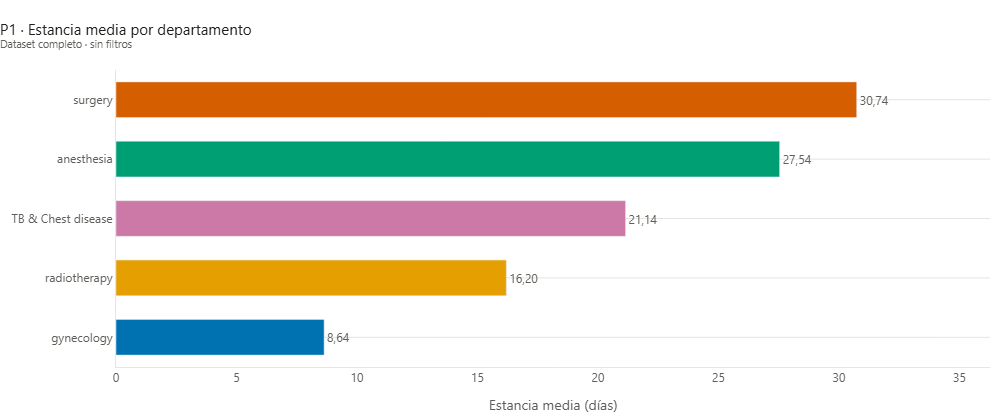

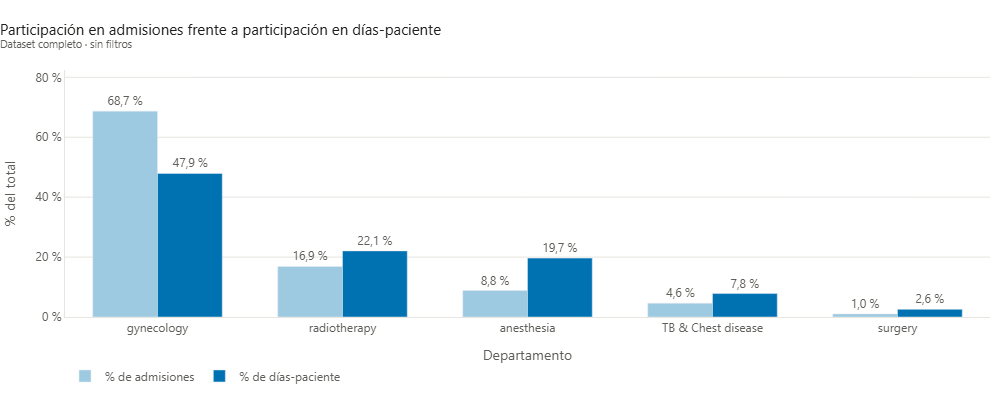

In [16]:
d = dash.dept_view(cubo, False)
mostrar(ch.dept_bars(d, "estancia_dias_media", "P1 · Estancia media por departamento", "Estancia media (días)", "Dataset completo · sin filtros"))
mostrar(ch.admissions_vs_patient_days(d, "Dataset completo · sin filtros"))

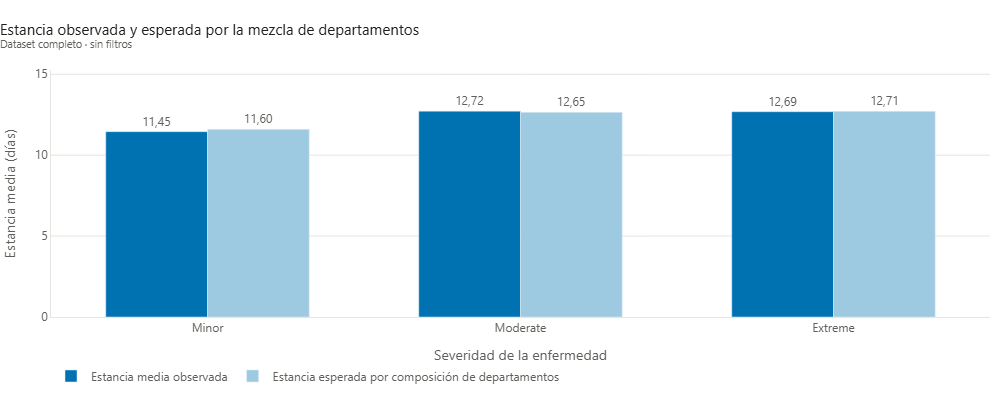

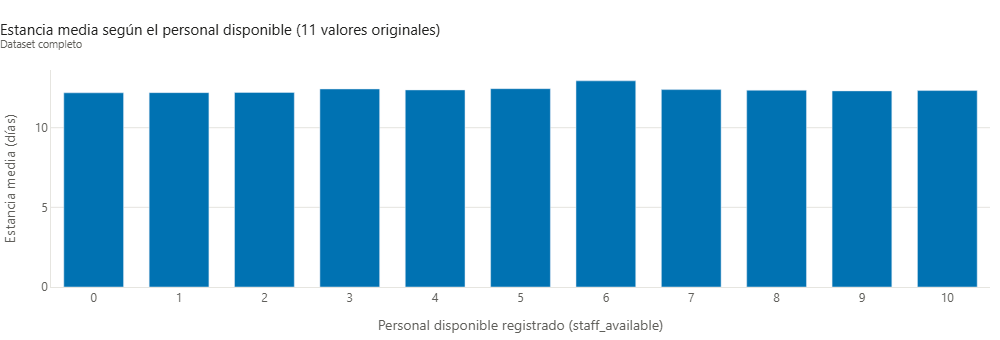

In [17]:
mostrar(ch.severity_observed_expected(bm.cube_expected_stay(cubo), "Dataset completo · sin filtros"))
mostrar(ch.staff_level_bars(dash.t["staff_level"], "Dataset completo"))

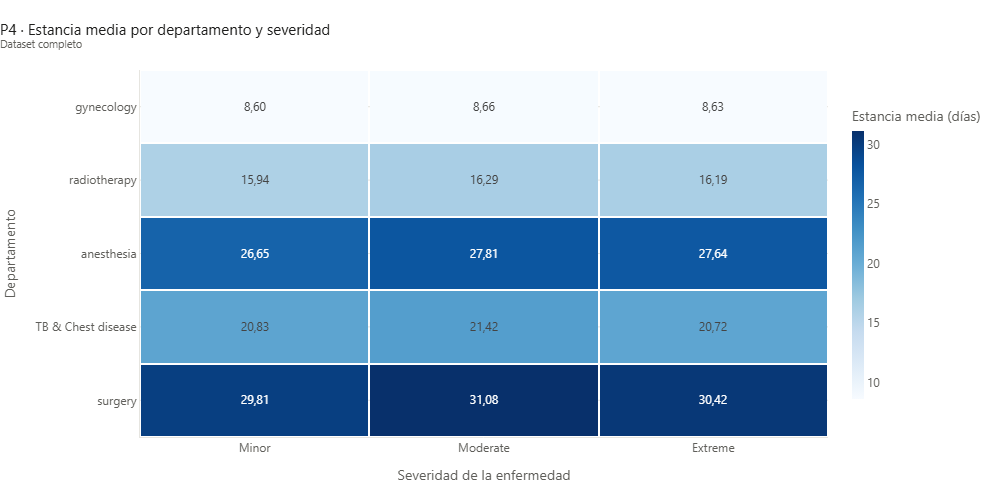

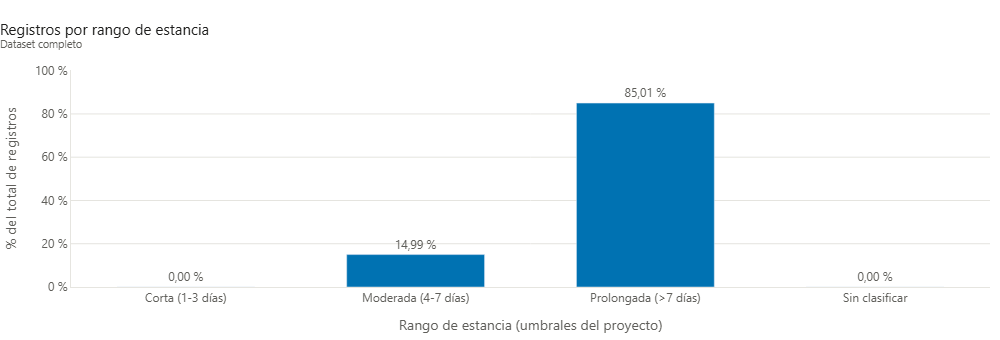

In [18]:
mostrar(ch.heatmap(bm.cube_group_metrics(cubo, ["department", "severity_of_illness"]), "estancia_dias_media",
                   "P4 · Estancia media por departamento y severidad", "Estancia media (días)", "Dataset completo"))
mostrar(ch.stay_range_bars(bm.cube_stay_range_table(cubo), "Dataset completo"))

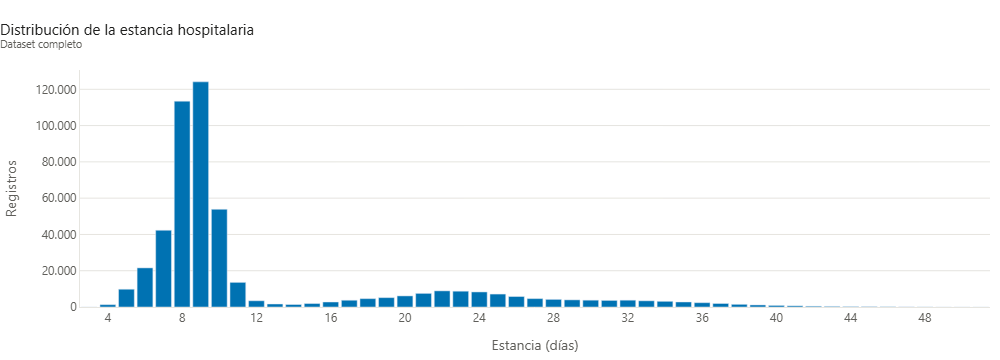

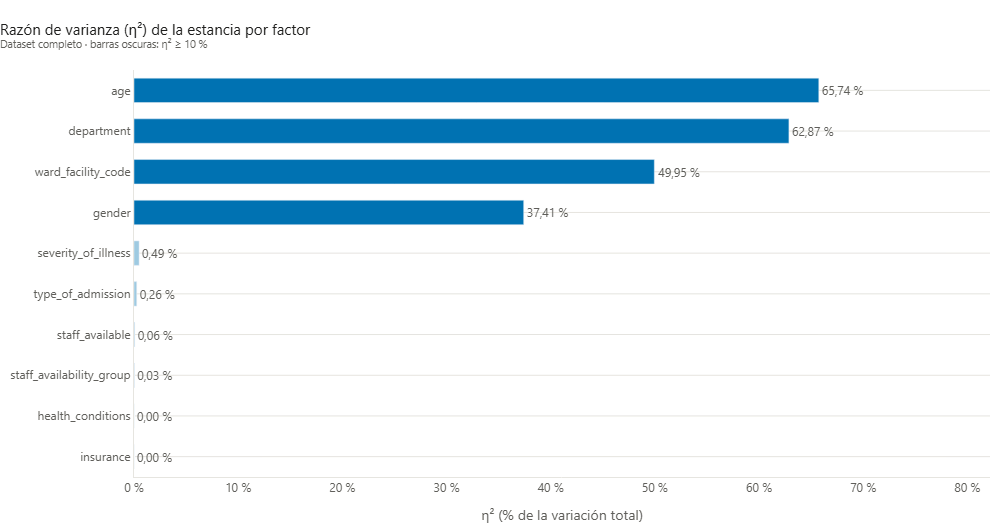

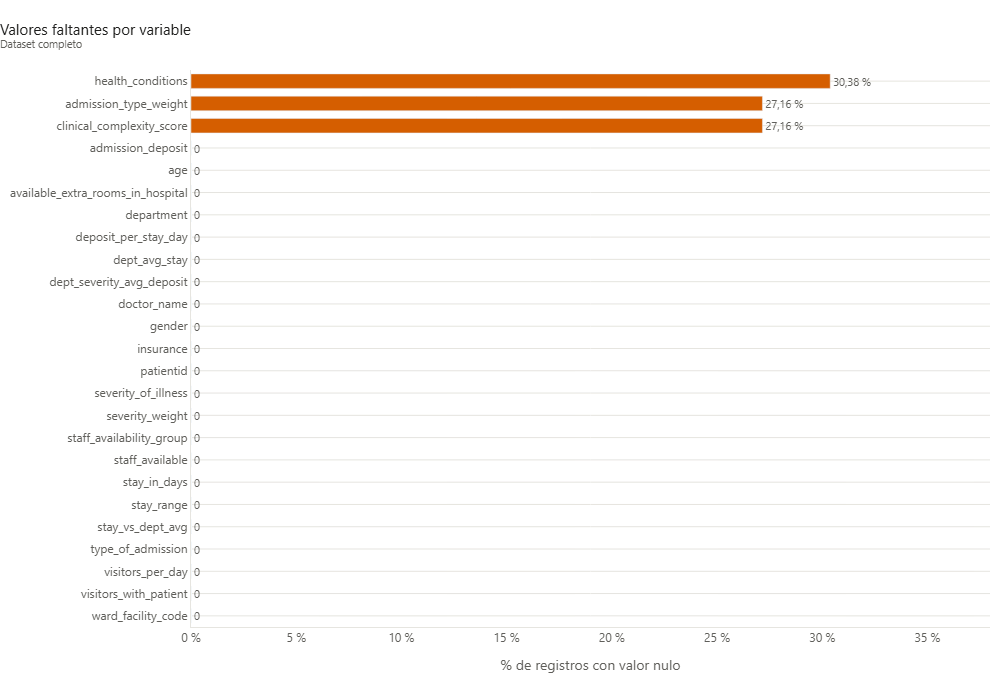

In [19]:
mostrar(ch.stay_distribution(bm.cube_stay_distribution(cubo), "Dataset completo"))
mostrar(ch.eta_bars(dash.t["eta_squared"], "stay_in_days", "Dataset completo"))
mostrar(ch.quality_nulls(dash.t["data_quality"], "Dataset completo"))

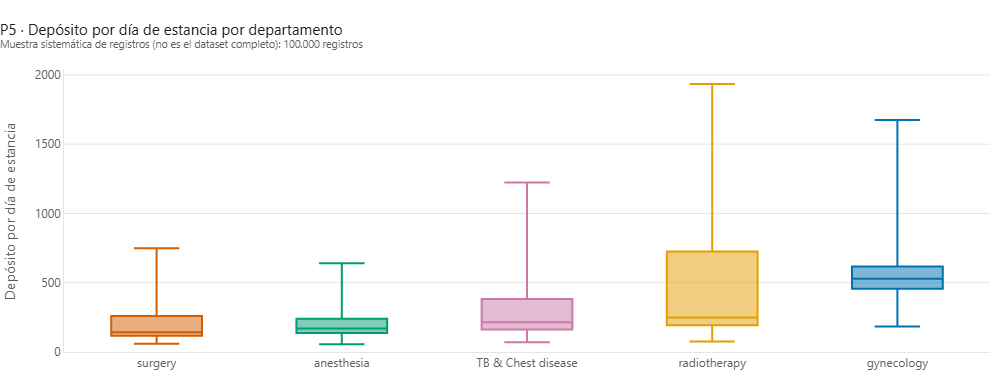

In [20]:
# Vista con registros individuales: siempre rotulada como muestra
mostrar(ch.sample_box(dash.sample, "deposit_per_stay_day", "Depósito por día de estancia", "P5 · Depósito por día de estancia por departamento"))

Ejemplo de filtro (lo mismo que hace la barra lateral): solo cirugía y severidad Extreme, recalculado con el dataset completo desde el cubo.

In [21]:
f = Filters({"department": ["surgery"], "severity_of_illness": ["Extreme"]}, [])
print(dash.universe_text(dash.filtered_cube(f), f))
bm.cube_group_metrics(dash.filtered_cube(f), "staff_availability_group")

Dataset completo filtrado (Departamento: surgery; Severidad de la enfermedad: Extreme): 1.703 de 500.000 registros (0,3 %). Cifras exactas calculadas desde el cubo agregado, no desde la muestra.


,staff_availability_group,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,dias_paciente,deposito_admision_validos,deposito_admision_media,deposito_admision_desv_est,pct_registros,pct_dias_paciente
0,Bajo (0-3),159,159,30.968553,34.0,11.086782,11.0,49.0,4924.0,159,4728.018301,819.700643,9.336465,9.505425
1,Medio (4-6),896,896,30.970982,35.0,10.932461,9.0,49.0,27750.0,896,4740.724875,913.786273,52.613036,53.569360
2,Alto (7+),648,648,29.518519,33.5,11.248752,9.0,50.0,19128.0,648,4710.973070,875.504336,38.050499,36.925215


## 14. Prueba automática de la app (sin navegador)

`AppTest` ejecuta `EA4/app.py` como lo haría Streamlit, recorre las diez secciones y prueba un filtro. Es una comprobación técnica (sin errores y con los elementos esperados), no una validación visual en el navegador.

In [22]:
import logging
from streamlit.testing.v1 import AppTest

for _n in ("streamlit", "streamlit.runtime.scriptrunner_utils.script_run_context"):
    logging.getLogger(_n).setLevel(logging.ERROR)
at = AppTest.from_file(str(ea4.EA4_DIR / "app.py"), default_timeout=240).run()
assert not at.exception, at.exception
resultado = []
for pagina in ["inicio", "pc1", "p1", "p2", "p3", "p4", "p5", "pc2", "pc3", "fin"]:
    at.sidebar.radio[0].set_value(pagina).run()
    assert not at.exception, (pagina, at.exception)
    resultado.append({"sección": pagina, "gráficos": len(at.get("plotly_chart")), "tablas": len(at.dataframe), "KPI": len(at.metric)})
display(pd.DataFrame(resultado))
at.sidebar.radio[0].set_value("pc1").run()
at.sidebar.multiselect[0].set_value(["surgery"]).run()
assert not at.exception
print("KPI con filtro department = surgery:", [(m.label, m.value) for m in at.metric])

,sección,gráficos,tablas,KPI
0,inicio,0,1,0
1,pc1,2,1,6
2,p1,4,1,0
3,p2,3,1,0
4,p3,4,1,3
5,p4,1,1,0
6,p5,7,4,0
7,pc2,4,1,0
8,pc3,1,2,0
9,fin,0,0,0


KPI con filtro department = surgery: [('Admisiones analizadas', '5.138'), ('Estancia media', '30,74 días'), ('Estancia mediana', '35 días'), ('Depósito medio', '4.753,70'), ('Departamentos', '1'), ('Nulos en variables de interés', '0,00 %')]


## 15. Conclusiones (generadas con las tablas del dataset completo)

In [23]:
texto = []
for q in ["P1", "P2", "P3", "P4", "P5", "PC1", "PC2", "PC3"]:
    r = resp[q]
    texto.append(f"**{q} · {ins.QUESTIONS[q]}**  \n{r['patron']}  \n*Respuesta:* {r['respuesta']}  \n*Revisión sugerida:* {r['decision']}  \n*Limitación:* {r['limitacion']}")
display(Markdown("\n\n".join(texto)))

**P1 · ¿Cómo varían la estancia y el depósito entre departamentos?**  
La estancia mediana va de 9 días en gynecology (n = 343.478) a 35 días en surgery (n = 5.138). gynecology concentra 68,7 % de las admisiones y 47,9 % de los días-paciente. El depósito medio varía 2,8 % entre departamentos, frente a 106,0 % de la estancia media.  
*Respuesta:* La estancia mediana del departamento con mayor estancia es 3,9 veces la del de menor estancia; el depósito medio cambia mucho menos que la estancia.  
*Revisión sugerida:* Revisar la carga de camas por servicio con los días-paciente además de las admisiones: gynecology pesa menos en días-paciente que en admisiones, y los servicios de estancia larga pesan más de lo que indica su volumen.  
*Limitación:* Descriptivo: no mide eficiencia ni causas de la estancia; el depósito de admisión registrado (unidad monetaria no documentada) no equivale a ingresos ni a costos.

**P2 · ¿Qué diferencias se observan según la severidad de la enfermedad?**  
Estancia media: Minor 11,45 días (n = 131.537); Moderate 12,72 días (n = 280.197); Extreme 12,69 días (n = 88.266). La mediana es 9 días en todas las categorías. Depósito medio de 4.693,85 a 4.749,10.  
*Respuesta:* Entre severidades la estancia media difiere como máximo 1,26 días; al descontar la mezcla de departamentos, la diferencia máxima entre estancia observada y esperada es de 0,14 días.  
*Revisión sugerida:* No usar la severidad registrada como indicador de la estancia esperada sin validar su definición; la diferencia residual (0,14 días de 1,26 días) indica que la mezcla de departamentos explica la mayor parte.  
*Limitación:* El orden Minor < Moderate < Extreme se asume por el nombre; la estandarización no demuestra causalidad.

**P3 · ¿Cómo se distribuyen la estancia y el depósito según la disponibilidad de personal?**  
La estancia media va de 12,26 días a 12,59 días entre grupos y el depósito medio varía 0,14 %. En el dataset completo, ρ de Spearman con la estancia = 0,005 y con el depósito = 0,001 (n = 500.000 pares válidos).  
*Respuesta:* Diferencia máxima de estancia media entre grupos: 0,33 días; asociación monótona despreciable (|ρ| < 0,1).  
*Revisión sugerida:* Verificar qué mide staff_available (momento, unidad, servicio) antes de usarlo en la planeación de personal o camas.  
*Limitación:* Una correlación cercana a cero no prueba ausencia de efecto; la variable no está documentada.

**P4 · ¿Qué patrones aparecen al cruzar departamento y severidad?**  
Dentro de un departamento, la estancia media cambia como máximo 1,27 días entre severidades; dentro de una misma severidad, la diferencia entre departamentos llega a 22,42 días. La celda más pequeña es surgery × Minor con 508 registros.  
*Respuesta:* Las diferencias entre departamentos superan a las de severidad dentro de cada departamento.  
*Revisión sugerida:* Comparar estancias entre servicios dentro de la misma severidad para no confundir el efecto de la mezcla de pacientes.  
*Limitación:* Las celdas pequeñas tienen estimaciones menos estables; el cruce no controla otros factores.

**P5 · ¿Qué utilidad aportan los indicadores derivados de EA3?**  
Rangos: Corta (1-3 días) 0,00 % (n = 18); Moderada (4-7 días) 14,99 % (n = 74.934); Prolongada (>7 días) 85,01 % (n = 425.048). El puntaje se calculó para 364.216 de 500.000 registros (72,84 %); su estancia media va de 11,60 días a 13,06 días. La mediana del depósito por día va de 141,45 (surgery) a 528,87 (gynecology).  
*Respuesta:* «Prolongada (>7 días)» concentra 85,0 % de los registros, por lo que con estos umbrales la segmentación discrimina poco; la estancia media no sigue un orden monótono con el puntaje de complejidad. El depósito por día refleja sobre todo la duración de la estancia.  
*Revisión sugerida:* Revisar los umbrales de stay_range con criterios de la institución y no usar el puntaje como predictor.  
*Limitación:* Umbrales y pesos son reglas del proyecto; Emergency no tiene peso en el puntaje; el depósito por día no es el costo diario y las visitas por día no miden carga asistencial.

**PC1 · ¿Cómo se distribuyen la estancia y el depósito en el conjunto de admisiones?**  
Estancia: media 12,38 días, mediana 9 días, desviación 7,91 días; 22,3 % de valores fuera de las vallas de Tukey. Depósito: media 4.722,32, mediana 4.627,00; 8,3 % de atípicos.  
*Respuesta:* La distribución de la estancia es asimétrica a la derecha (media mayor que la mediana); el rango intercuartílico del depósito es 1.019,90.  
*Revisión sugerida:* Reportar la estancia con la mediana y su distribución, no solo con la media.  
*Limitación:* Los atípicos se conservan: no hay evidencia de que sean errores.

**PC2 · ¿Qué otras variables se relacionan descriptivamente con la estancia y el depósito?**  
Factores con mayor η² para la estancia: age 65,7 %; department 62,9 %; ward_facility_code 50,0 %; gender 37,4 %. Para el depósito, el máximo es ward_facility_code con 1,20 %. La correlación de mayor magnitud es visitors_with_patient – admission_deposit (ρ = -0,151).  
*Respuesta:* age es el factor con mayor η² para la estancia (65,7 %); para el depósito ningún factor supera 1,20 %. Los η² de factores distintos pueden solaparse porque los factores están relacionados entre sí.  
*Revisión sugerida:* Analizar en conjunto los factores con mayor η² (cruces) antes de atribuir la estancia a uno solo.  
*Limitación:* η² y ρ son medidas de asociación, no de causalidad.

**PC3 · ¿Qué limitaciones de calidad condicionan la interpretación?**  
Variables con nulos: health_conditions 30,38 %; admission_type_weight 27,16 %; clinical_complexity_score 27,16 %. Variables completas: 22 de 25.  
*Respuesta:* 3 variables tienen nulos; los nulos se conservan y no se imputan, y los indicadores que no pueden calcularse quedan vacíos en lugar de cero.  
*Revisión sugerida:* Solicitar a la fuente la definición de las variables y del valor nulo antes de usar estas columnas en decisiones.  
*Limitación:* La ficha del dataset no documenta licencia, procedencia, periodo ni definiciones de columnas.

**Cómo abrir la app.** Desde la raíz del repositorio:

```bash
streamlit run EA4/app.py
```

Las métricas oficiales provienen de las tablas del dataset completo; la muestra solo alimenta vistas de registros individuales rotuladas como tales. Ninguna diferencia observada se interpreta como causal.